# Phase 4 · 1/3 — Le KPI et sa série temporelle

**VIGIE · Groupe BI 5** — Raed Meddeb · Salsabil Ben Elhadj · Salah Chebbi · Ines Ayed
Projet Intégré, ESPRIT School of Business · Tuteurs : Aymen Ben Brik et Hela Hammami

---

| Étape | Contenu |
|---|---|
| 1 | Choix du KPI et justification métier |
| 2 | Construction de la série (grain compte, semaines à zéro) |
| 3 | Pics : identification et traitement des opérations de masse |
| 4 | Tendance et ruptures de régime |
| 5 | Saisonnalité |
| 6 | Autocorrélation (ACF / PACF) et stationnarité |
| 7 | Conséquences pour la modélisation |

*Les dates du jeu de données ont été décalées par l'anonymisation : on lit des durées et des évolutions, jamais
un calendrier réel.*

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss

RACINE = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(RACINE))
from vigie import config, donnees, series, style

warnings.filterwarnings("ignore")
style.appliquer()
C = config.COULEURS
fr = style.milliers

## 1. Le KPI retenu : le nombre hebdomadaire de clôtures de comptes

**Définition.** Pour chaque semaine (repérée par son lundi), le nombre de comptes dont la *première* date de
clôture tombe dans cette semaine.

**Pourquoi ce KPI ?**

* **C'est la mesure directe du churn** : le churn est défini par la clôture d'un compte. Le KPI compte donc
  exactement l'événement que l'on veut anticiper.
* **Il est actionnable** : prévoir le volume de clôtures de la semaine suivante permet de dimensionner les équipes
  de rétention et de back-office, et de repérer une semaine anormale dès qu'elle s'écarte de la prévision.
* **Il est disponible au bon grain** : les dates de clôture sont ramenées au lundi, ce qui donne une série
  hebdomadaire d'environ 200 points. Au mois, on n'aurait que 47 points : trop peu pour un réseau récurrent.

**Pourquoi pas le taux de clôture ?** Un taux exigerait de connaître, chaque semaine, le stock de comptes ouverts.
Or la date d'ouverture est vide pour 68 % des comptes clos : ce stock ne peut pas être reconstitué proprement.
Le *nombre* de clôtures, lui, ne dépend que de la date de clôture, toujours renseignée.

## 2. Construction de la série

In [2]:
df = donnees.charger()
comptes = donnees.grain_compte(df)                       # une ligne par compte, première clôture retenue
clos = comptes[comptes["CHURN"] == 1]

serie = series.serie_hebdo(clos["ACCT_CLOSE_DATE"])      # comptage par lundi, semaines à zéro ajoutées

lignes_brutes = df[df["ACCOUNT_STATUS"] == "Closed"]
print(f"Lignes « Closed » dans le fichier        : {fr(len(lignes_brutes))}")
print(f"Comptes clos après dédoublonnage         : {fr(len(clos))}")
print(f"Période couverte                         : {serie.index[0]:%d/%m/%Y} → {serie.index[-1]:%d/%m/%Y}")
print(f"Nombre de semaines                       : {len(serie)}  (≈ {len(serie) / 52:.1f} ans)")
print(f"Semaines sans aucune clôture (ajoutées)  : {int((serie == 0).sum())}")
print(f"Total des clôtures dans la série         : {fr(serie.sum())}")
assert serie.sum() == len(clos)                          # aucune clôture perdue ni comptée deux fois

Lignes « Closed » dans le fichier        : 177 270
Comptes clos après dédoublonnage         : 148 215
Période couverte                         : 13/04/2020 → 19/02/2024
Nombre de semaines                       : 202  (≈ 3.9 ans)
Semaines sans aucune clôture (ajoutées)  : 11
Total des clôtures dans la série         : 148 215


**Trois précautions ont été prises :**

1. **Grain compte.** Compter les lignes du fichier donnerait 177 270 clôtures au lieu de 148 215 : les comptes
   répétés gonfleraient la série de près de 20 %.
2. **Première date de clôture.** 11 807 comptes portent plusieurs dates ; on retient la première.
3. **Semaines à zéro.** Une semaine absente du fichier n'est pas une donnée manquante : c'est une semaine à
   **zéro clôture**. Elles sont ajoutées, sinon la série n'aurait pas un pas de temps régulier.

,count,mean,std,min,25%,50%,75%,max
Clôtures par semaine,202.0,733.7,2693.1,0.0,6.0,165.5,369.5,24295.0


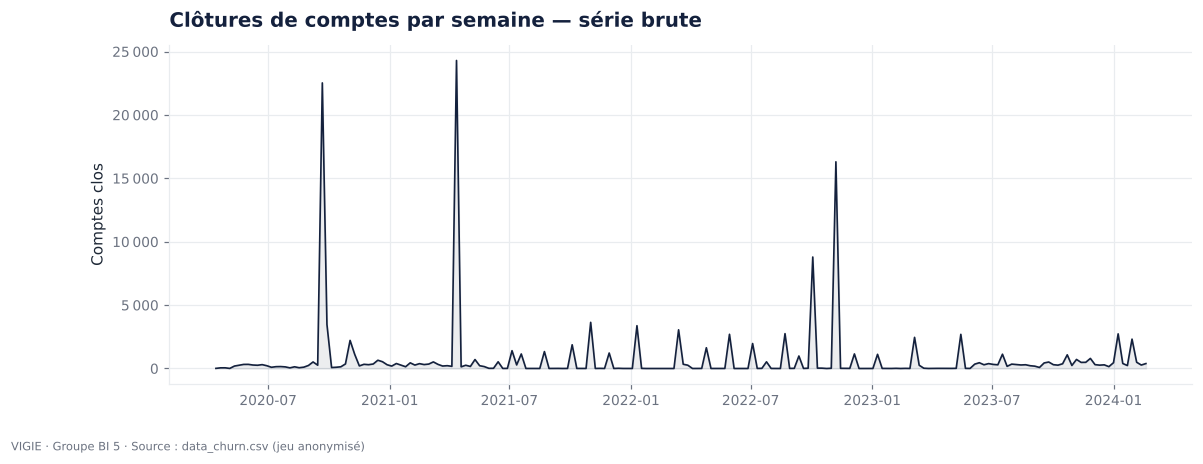

In [3]:
display(serie.describe().round(1).to_frame("Clôtures par semaine").T)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(serie.index, serie.values, color=C["encre"], lw=1.1)
ax.fill_between(serie.index, serie.values, color=C["encre"], alpha=0.08)
ax.yaxis.set_major_formatter(style.milliers)
ax.set_title("Clôtures de comptes par semaine — série brute")
ax.set_ylabel("Comptes clos")
style.enregistrer(fig, "04_serie_brute")
plt.show()

**Lecture.** La série brute est illisible : quelques semaines écrasent tout le reste. La **médiane** est d'environ
165 clôtures par semaine alors que la **moyenne** dépasse 730 et que le maximum dépasse 24 000. Avant toute analyse,
il faut traiter ces pics.

## 3. Pics : les opérations de masse

### 3.1 Identification

**Règle retenue.** On classe les semaines par volume décroissant et on retient **le plus petit ensemble de semaines
qui cumule la moitié des clôtures**. Cette règle n'a aucun seuil arbitraire et se relit immédiatement en termes
métier : « ces semaines pèsent autant que toutes les autres réunies ».

In [4]:
masse = series.semaines_de_masse(serie)                  # plus petit ensemble cumulant 50 % du volume
tri = serie.sort_values(ascending=False)
concentration = pd.DataFrame({
    "Semaine": tri.index[:8].strftime("%d/%m/%Y"),
    "Clôtures": tri.values[:8],
    "Part du total": (tri.values[:8] / serie.sum()),
    "Part cumulée": (tri.cumsum().values[:8] / serie.sum()),
    "Opération de masse": ["Oui" if s in masse else "Non" for s in tri.index[:8]],
})
display(concentration.style.format({"Clôtures": fr, "Part du total": "{:.1%}", "Part cumulée": "{:.1%}"}).hide(axis="index"))
print(f"{len(masse)} semaines sur {len(serie)} ({len(masse) / len(serie):.1%}) portent {serie[masse].sum() / serie.sum():.1%} des clôtures.")

Semaine,Clôtures,Part du total,Part cumulée,Opération de masse
12/04/2021,24 295,16.4%,16.4%,Oui
21/09/2020,22 525,15.2%,31.6%,Oui
07/11/2022,16 301,11.0%,42.6%,Oui
03/10/2022,8 794,5.9%,48.5%,Oui
01/11/2021,3 641,2.5%,51.0%,Oui
28/09/2020,3 470,2.3%,53.3%,Non
10/01/2022,3 376,2.3%,55.6%,Non
14/03/2022,3 052,2.1%,57.7%,Non


5 semaines sur 202 (2.5%) portent 51.0% des clôtures.


In [5]:
# Ces semaines sont-elles de nature différente ? On regarde le motif de clôture.
motif_masse = clos["ACCT_CLOSE_DATE"].isin(masse)
part_autre = clos.groupby(motif_masse)["CLOSURE_REASON"].apply(lambda s: (s == "RSN01").mean())
info_compte = clos.groupby(motif_masse)["ACCT_BALANCE"].apply(lambda s: s.isna().mean())
nature = pd.DataFrame({
    "Comptes clos": clos.groupby(motif_masse).size(),
    "Part du motif « Autre » (RSN01)": part_autre,
    "Part des comptes sans solde renseigné": info_compte,
})
nature.index = ["Semaines ordinaires", "Semaines de masse"]
display(nature.style.format({"Comptes clos": fr, "Part du motif « Autre » (RSN01)": "{:.1%}",
                             "Part des comptes sans solde renseigné": "{:.1%}"}))

,Comptes clos,Part du motif « Autre » (RSN01),Part des comptes sans solde renseigné
Semaines ordinaires,72 659,61.9%,53.8%
Semaines de masse,75 556,99.5%,81.3%


**Lecture.** Cinq semaines — soit 2,5 % de la série — concentrent **51 % des clôtures**. On retrouve le constat du
document de description des données. Ces semaines ne ressemblent pas aux autres : le motif de clôture y est
« Autre » dans 99,5 % des cas (62 % les autres semaines) et 81 % des comptes concernés n'ont plus d'information de
solde (54 % les autres semaines). Ce sont des **opérations de masse** (clôtures par lots), pas des départs
individuels de clients.

### 3.2 Traitement : une série corrigée

Trois traitements étaient possibles :

| Option | Principe | Pourquoi nous ne la retenons pas / la retenons |
|---|---|---|
| Laisser tel quel | le modèle apprend les pics | impossible : une opération de masse est une décision de gestion, elle n'est pas prévisible à partir du passé de la série, et elle domine l'erreur |
| Variable d'intervention | ajouter un indicateur 0/1 « semaine de masse » | l'indicateur n'est connu qu'*après coup* : il ne peut pas servir à prévoir le futur |
| **Série corrigée** | remplacer la valeur des 5 semaines par un niveau ordinaire | **retenue** : on prévoit l'activité courante de clôture, qui est celle que le métier peut anticiper |

**Correction appliquée.** Chaque semaine de masse est remplacée par la **médiane des 4 semaines précédentes et des
4 suivantes** (hors autres semaines de masse). La médiane est robuste aux pics voisins. L'indicateur de semaine de
masse est conservé à part pour l'affichage : on ne cache pas ces opérations, on les sort du signal à prévoir.

In [6]:
corrigee = series.corriger_masse(serie, masse)
avant_apres = pd.DataFrame({"Série brute": serie[masse], "Série corrigée": corrigee[masse]})
avant_apres.index = avant_apres.index.strftime("%d/%m/%Y")
display(avant_apres.style.format(fr))
print(f"Total brut : {fr(serie.sum())}   |   Total corrigé : {fr(corrigee.sum())}   "
      f"|   Volume retiré : {fr(serie.sum() - corrigee.sum())} ({1 - corrigee.sum() / serie.sum():.1%})")
display(corrigee.describe().round(1).to_frame("Série corrigée").T)

,Série brute,Série corrigée
semaine,,
21/09/2020,22 525,186
12/04/2021,24 295,208
01/11/2021,3 641,4
03/10/2022,8 794,20
07/11/2022,16 301,16


Total brut : 148 215   |   Total corrigé : 73 093   |   Volume retiré : 75 122 (50.7%)


,count,mean,std,min,25%,50%,75%,max
Série corrigée,202.0,361.8,655.2,0.0,5.2,148.5,340.2,3470.0


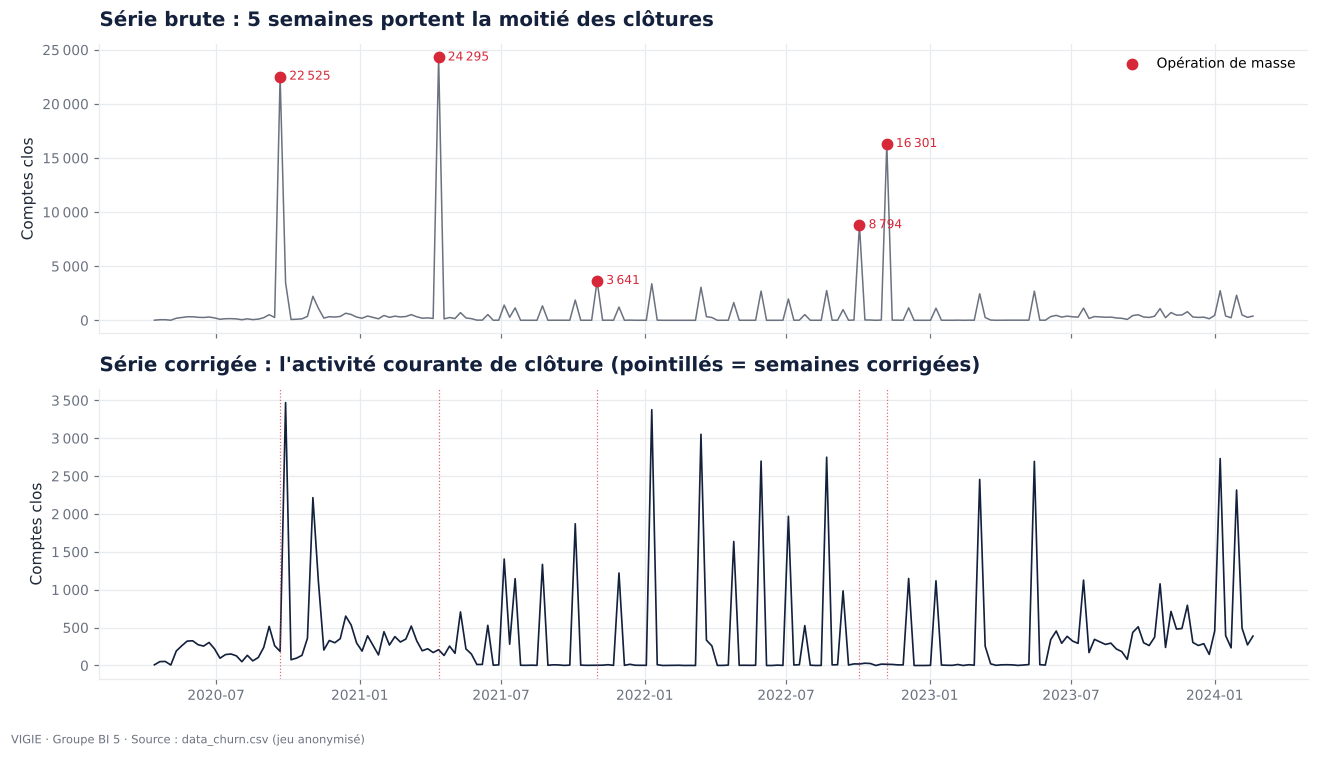

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.6), sharex=True)
axes[0].plot(serie.index, serie.values, color=C["gris"], lw=1)
axes[0].scatter(masse, serie[masse], color=C["churn"], zorder=3, s=45, label="Opération de masse")
for s in masse:
    axes[0].annotate(fr(serie[s]), (s, serie[s]), textcoords="offset points", xytext=(6, -2), fontsize=8, color=C["churn"])
axes[0].set_title("Série brute : 5 semaines portent la moitié des clôtures")
axes[0].legend(loc="upper right")
axes[1].plot(corrigee.index, corrigee.values, color=C["encre"], lw=1.1)
for s in masse:
    axes[1].axvline(s, color=C["churn"], lw=0.8, ls=":", alpha=0.7)
axes[1].set_title("Série corrigée : l'activité courante de clôture (pointillés = semaines corrigées)")
for ax in axes:
    ax.yaxis.set_major_formatter(style.milliers)
    ax.set_ylabel("Comptes clos")
fig.tight_layout()
style.enregistrer(fig, "04_serie_corrigee")
plt.show()

Une fois les cinq opérations de masse retirées, la série redevient lisible. Elle reste **très irrégulière** : il
subsiste 22 semaines à plus de 1 000 clôtures (11 % des semaines, 60 % du volume corrigé). Elles sont trop
nombreuses et trop récurrentes pour être traitées comme des exceptions : elles font partie du fonctionnement
normal et sont laissées dans la série. C'est la principale difficulté de la prévision.

## 4. Tendance et ruptures de régime

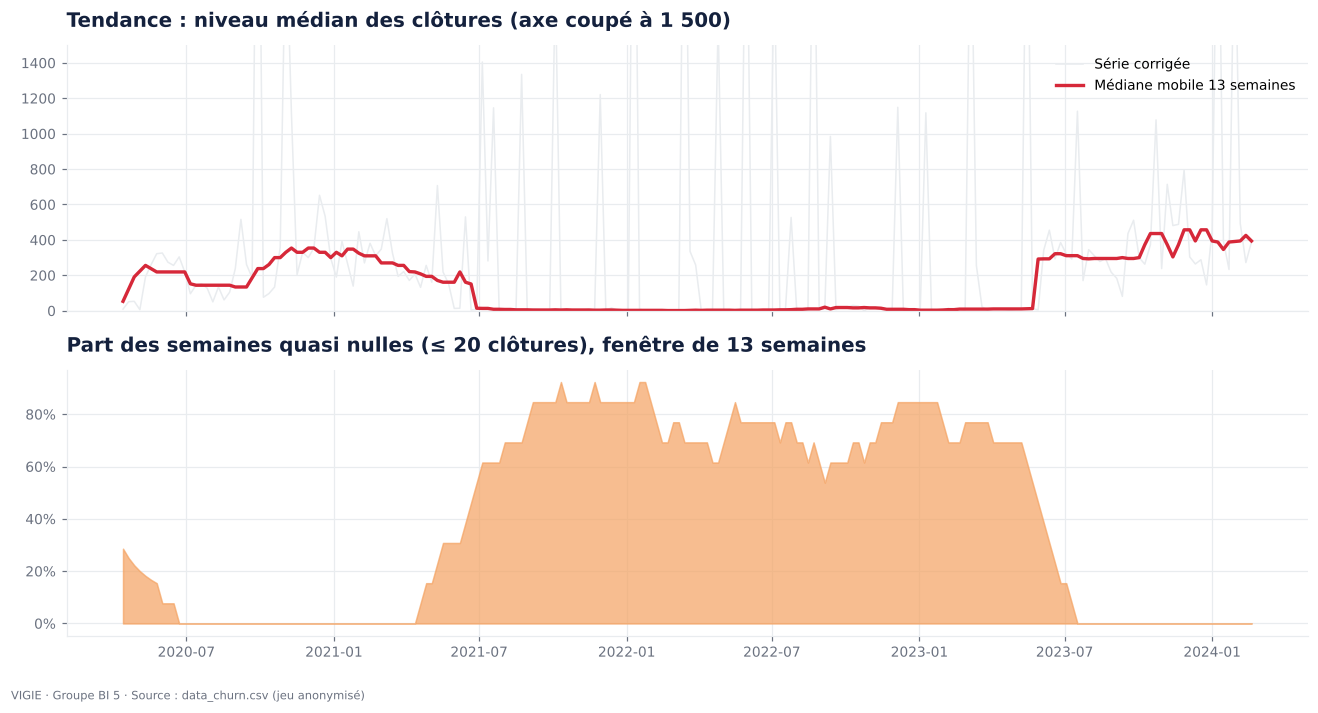

In [8]:
mediane_mobile = corrigee.rolling(13, center=True, min_periods=7).median()      # ≈ un trimestre
part_quasi_nulle = (corrigee <= 20).rolling(13, center=True, min_periods=7).mean()

fig, axes = plt.subplots(2, 1, figsize=(12, 6.2), sharex=True)
axes[0].plot(corrigee.index, corrigee.values, color=C["brume"], lw=1, label="Série corrigée")
axes[0].plot(mediane_mobile.index, mediane_mobile.values, color=C["churn"], lw=2.2, label="Médiane mobile 13 semaines")
axes[0].set_ylim(0, 1500)
axes[0].set_title("Tendance : niveau médian des clôtures (axe coupé à 1 500)")
axes[0].legend(loc="upper right")
axes[1].fill_between(part_quasi_nulle.index, part_quasi_nulle.values, color=C["ambre"], alpha=0.7)
axes[1].yaxis.set_major_formatter(style.pourcent)
axes[1].set_title("Part des semaines quasi nulles (≤ 20 clôtures), fenêtre de 13 semaines")
fig.tight_layout()
style.enregistrer(fig, "04_tendance_regimes")
plt.show()

In [9]:
# Découpage en régimes : on repère les changements d'état « semaines quasi nulles majoritaires ».
etat = (part_quasi_nulle > 0.5).astype(int)
ruptures = etat.index[etat.diff().abs() == 1]
bornes = [corrigee.index[0], *ruptures, corrigee.index[-1] + pd.Timedelta(weeks=1)]
regimes = []
for i, (a, b) in enumerate(zip(bornes, bornes[1:]), start=1):
    bloc = corrigee[(corrigee.index >= a) & (corrigee.index < b)]
    regimes.append({
        "Régime": i, "Début": f"{bloc.index[0]:%d/%m/%Y}", "Fin": f"{bloc.index[-1]:%d/%m/%Y}", "Semaines": len(bloc),
        "Médiane": bloc.median(), "Moyenne": round(bloc.mean(), 1),
        "Semaines ≤ 20 clôtures": f"{(bloc <= 20).mean():.0%}", "Semaines à zéro": int((bloc == 0).sum()),
        "Maximum": int(bloc.max()),
    })
regimes = pd.DataFrame(regimes).set_index("Régime")
display(regimes)

,Début,Fin,Semaines,Médiane,Moyenne,Semaines ≤ 20 clôtures,Semaines à zéro,Maximum
Régime,,,,,,,,
1,13/04/2020,21/06/2021,63,221.0,334.0,8%,0,3470
2,28/06/2021,22/05/2023,100,6.0,329.8,75%,11,3376
3,29/05/2023,19/02/2024,39,322.0,488.9,3%,0,2732


**Lecture — tendance et ruptures.** La série n'a pas de tendance régulière à la hausse ou à la baisse. Elle change
de **régime** :

* **Régime 1 — flux continu (63 semaines).** Des clôtures chaque semaine, 221 en médiane.
* **Régime 2 — traitement par lots (100 semaines).** Trois semaines sur quatre sont quasi vides (médiane : 6) et
  les clôtures arrivent par paquets espacés de plusieurs semaines. Les 11 semaines à zéro sont toutes dans ce régime.
  La *moyenne* (330) reste pourtant proche de celle du régime 1 : le volume est le même, seul le rythme change.
* **Régime 3 — retour au flux continu (39 semaines).** À nouveau des clôtures chaque semaine, à un niveau plus
  élevé qu'au départ (médiane 322).

C'est le fait le plus important de l'analyse : le *rythme* de la série tient au **mode de traitement** des clôtures
(au fil de l'eau ou par lots) autant qu'au comportement des clients. La période de test — les 40 dernières
semaines — coïncide presque exactement avec le régime 3 (39 semaines).

## 5. Saisonnalité

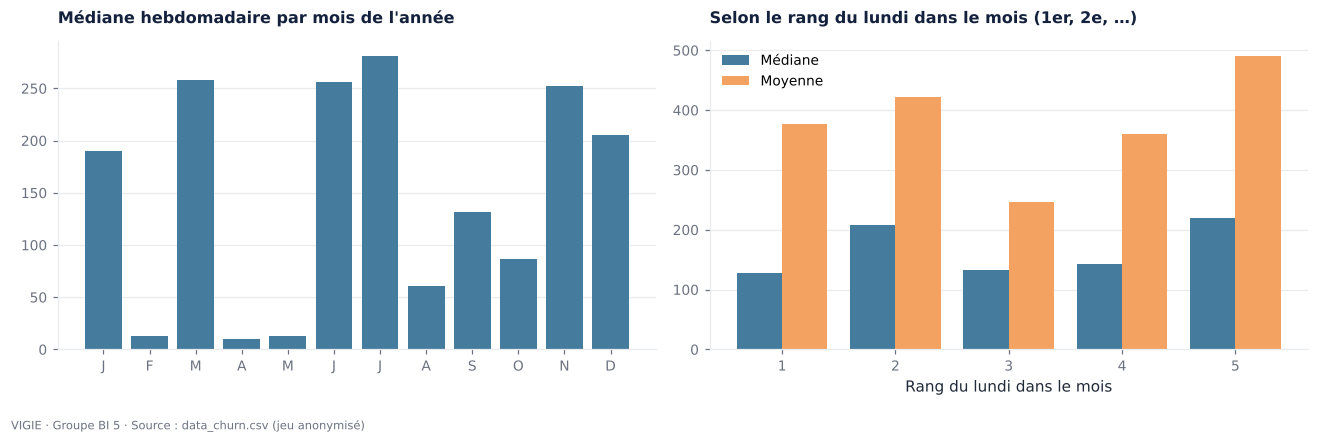

,Semaines,Médiane,Total
semaine,,,
2020,38,228.5,14476
2021,52,145.0,13923
2022,52,5.5,18983
2023,52,263.5,18426
2024,8,425.5,7285


,Médiane,Moyenne
Rang du lundi dans le mois,,
1,128.0,377.0
2,208.0,421.0
3,132.0,246.0
4,142.0,359.0
5,220.0,490.0


In [10]:
par_mois = corrigee.groupby(corrigee.index.month).median()
rang_dans_mois = ((corrigee.index.day - 1) // 7 + 1)
par_rang = corrigee.groupby(rang_dans_mois).agg(["median", "mean"])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(par_mois.index, par_mois.values, color=C["ciel"])
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
axes[0].set_title("Médiane hebdomadaire par mois de l'année", fontsize=10.5)
axes[1].bar(par_rang.index - 0.2, par_rang["median"], width=0.4, color=C["ciel"], label="Médiane")
axes[1].bar(par_rang.index + 0.2, par_rang["mean"], width=0.4, color=C["ambre"], label="Moyenne")
axes[1].set_title("Selon le rang du lundi dans le mois (1er, 2e, …)", fontsize=10.5)
axes[1].set_xlabel("Rang du lundi dans le mois")
axes[1].legend()
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.tight_layout()
style.enregistrer(fig, "04_saisonnalite")
plt.show()

annees_completes = corrigee.groupby(corrigee.index.year).agg(Semaines="size", Médiane="median", Total="sum")
display(annees_completes)
display(par_rang.round(0).rename(columns={"median": "Médiane", "mean": "Moyenne"}).rename_axis("Rang du lundi dans le mois"))

**Lecture — saisonnalité.**

* **Saisonnalité annuelle : non démontrable.** La série couvre moins de quatre ans, dont deux en régime « par lots ».
  Les écarts entre mois reflètent surtout le régime dans lequel tombent ces mois, pas un cycle annuel. De plus,
  les dates étant décalées, un mois du jeu de données ne correspond pas à un mois réel.
* **Effet « rang dans le mois » : aucun.** Aucun rang de lundi ne se détache de façon stable : les médianes vont
  de 128 à 220 et les moyennes de 246 à 490, sans ordre lisible. Les lots ne tombent donc pas à date fixe dans le mois.

Nous ne retenons donc **pas de composante saisonnière calendaire**. S'il existe un rythme, il est à chercher dans
la série elle-même : c'est l'objet de l'autocorrélation.

## 6. Autocorrélation et stationnarité

On travaille sur `log(1 + clôtures)` : la transformation logarithmique ramène les pics à une échelle comparable au
reste de la série (le `+ 1` permet de traiter les semaines à zéro).

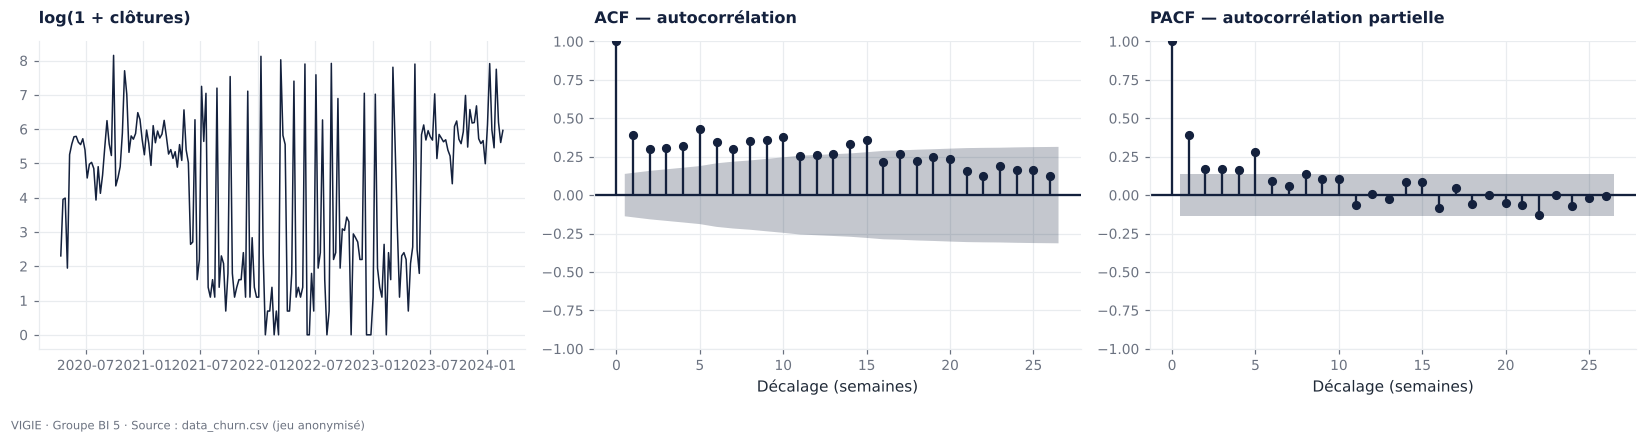

Décalage (semaines),1,2,3,4,5,6,7,8,9,10,11,12
ACF,0.39,0.30,0.31,0.32,0.43,0.35,0.30,0.35,0.36,0.38,0.26,0.26
PACF,0.39,0.17,0.17,0.16,0.28,0.09,0.06,0.14,0.11,0.11,-0.06,0.01


Seuil de significativité à 95 % : ± 0.14


In [11]:
log_serie = np.log1p(corrigee)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(log_serie.index, log_serie.values, color=C["encre"], lw=1)
axes[0].set_title("log(1 + clôtures)", fontsize=10.5)
plot_acf(log_serie, lags=26, ax=axes[1], color=C["encre"], vlines_kwargs={"colors": C["encre"]})
axes[1].set_title("ACF — autocorrélation", fontsize=10.5)
plot_pacf(log_serie, lags=26, ax=axes[2], color=C["encre"], vlines_kwargs={"colors": C["encre"]}, method="ywm")
axes[2].set_title("PACF — autocorrélation partielle", fontsize=10.5)
for ax in axes[1:]:
    ax.set_xlabel("Décalage (semaines)")
fig.tight_layout()
style.enregistrer(fig, "04_acf_pacf")
plt.show()

from statsmodels.tsa.stattools import acf, pacf
ac, pac = acf(log_serie, nlags=12), pacf(log_serie, nlags=12, method="ywm")
display(pd.DataFrame({"ACF": ac[1:], "PACF": pac[1:]}, index=pd.RangeIndex(1, 13, name="Décalage (semaines)")).round(2).T)
print(f"Seuil de significativité à 95 % : ± {1.96 / np.sqrt(len(log_serie)):.2f}")

In [12]:
def tests_stationnarite(s: pd.Series, nom: str) -> dict:
    adf_stat, adf_p = adfuller(s.dropna(), autolag="AIC")[:2]
    kpss_stat, kpss_p = kpss(s.dropna(), regression="c", nlags="auto")[:2]
    return {"Série": nom, "ADF — statistique": round(adf_stat, 2), "ADF — p-value": round(adf_p, 4),
            "ADF : stationnaire ?": "Oui" if adf_p < 0.05 else "Non",
            "KPSS — statistique": round(kpss_stat, 2), "KPSS — p-value": round(kpss_p, 3),
            "KPSS : stationnaire ?": "Oui" if kpss_p > 0.05 else "Non"}


stationnarite = pd.DataFrame([
    tests_stationnarite(corrigee.astype(float), "Série corrigée"),
    tests_stationnarite(log_serie, "log(1 + série)"),
    tests_stationnarite(log_serie.diff(), "log(1 + série), différenciée"),
]).set_index("Série")
display(stationnarite)

,ADF — statistique,ADF — p-value,ADF : stationnaire ?,KPSS — statistique,KPSS — p-value,KPSS : stationnaire ?
Série,,,,,,
Série corrigée,-11.64,0.0000,Oui,0.17,0.100,Oui
log(1 + série),-1.14,0.6982,Non,0.49,0.043,Non
"log(1 + série), différenciée",-8.54,0.0000,Oui,0.16,0.100,Oui


**Comment lire les deux tests.** Ils posent la question dans des sens opposés :

* **ADF** — hypothèse nulle : la série *n'est pas* stationnaire. Une p-value < 0,05 conclut à la stationnarité.
* **KPSS** — hypothèse nulle : la série *est* stationnaire. Une p-value < 0,05 conclut à la non-stationnarité.

Quand les deux tests s'accordent, la conclusion est solide ; quand ils divergent, la série est à la frontière
(typiquement : stationnaire par morceaux, avec des changements de niveau).

**Lecture — autocorrélation.**

* L'**ACF** est significative à tous les décalages de 1 à 12 et décroît très lentement (de 0,39 à 0,26) : une
  semaine ressemble aux semaines voisines parce qu'elle appartient au même **régime**. Cette persistance est la
  signature d'un niveau qui change dans le temps.
* La **PACF** est nette aux décalages 1 à 5 (0,39 puis 0,16 à 0,28), puis retombe autour du seuil. Le pic au
  **décalage 5** (ACF 0,43, la plus forte) indique un rythme d'environ cinq semaines : c'est l'espacement typique
  des lots du régime 2.
* Conséquence : une **fenêtre de 8 semaines** couvre tous les décalages utiles, dont le rythme de cinq semaines.

**Lecture — stationnarité.**

* Sur l'échelle **logarithmique**, celle sur laquelle on modélise, les deux tests s'accordent : la série
  **n'est pas stationnaire** (ADF : p = 0,70 ; KPSS : p = 0,04). Les changements de régime sont des changements de niveau.
* **Une différenciation suffit** : la série différenciée est stationnaire pour les deux tests. Un modèle ARIMA
  devra donc prendre `d = 1`.
* En niveau brut, les tests concluent à la stationnarité, mais c'est trompeur : les pics dominent la variance et
  masquent les changements de niveau. C'est une raison de plus de travailler en logarithme.

## 7. Ce que l'analyse implique pour la modélisation

In [13]:
significatifs = [k for k in range(1, 13) if abs(ac[k]) > 1.96 / np.sqrt(len(log_serie))]
constats = {
    "Décalages dont l'ACF est significative (1 à 12)": significatifs,
    "ACF au décalage 1": round(float(ac[1]), 2),
    "ACF maximale (décalages 1 à 12)": f"{max(ac[1:], key=abs):.2f} au décalage {int(np.argmax(np.abs(ac[1:]))) + 1}",
    "Semaines à zéro": int((corrigee == 0).sum()),
    "Coefficient de variation (écart-type / moyenne)": round(float(corrigee.std() / corrigee.mean()), 2),
}
display(pd.Series(constats, name="Valeur").to_frame())

,Valeur
Décalages dont l'ACF est significative (1 à 12),"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]"
ACF au décalage 1,0.39
ACF maximale (décalages 1 à 12),0.43 au décalage 5
Semaines à zéro,11
Coefficient de variation (écart-type / moyenne),1.81


| Constat | Décision de modélisation |
|---|---|
| 5 opérations de masse = 51 % des clôtures | Série **corrigée** ; indicateur de masse conservé pour l'affichage |
| Distribution très asymétrique, 11 semaines à zéro | Transformation `log(1 + x)` ; erreur absolue comme fonction de perte |
| **MAPE non défini** sur les semaines à zéro | Évaluation en **MAE** et **RMSE** uniquement |
| Trois régimes, pas de saisonnalité calendaire | Pas de composante saisonnière ; découpage **chronologique** strict |
| PACF utile jusqu'à 5 semaines, pic d'ACF à 5 | **Fenêtre glissante de 8 semaines** |
| Non stationnaire en log, stationnaire après différenciation | ARIMA de référence avec `d = 1` |
| ≈ 200 points seulement, pics récurrents | Réseau **petit** (une couche) ; comparaison obligatoire à des références simples |

**Ce qu'on peut raisonnablement attendre.** Avec 202 semaines, trois régimes et des pics récurrents, aucun modèle
ne prévoira les pics. L'objectif réaliste est de prévoir correctement le **niveau courant** des clôtures, et de
faire mieux que la prévision naïve. C'est ce que mesure le notebook suivant.

➡ Suite : `02_lstm_rnn.ipynb`.

In [14]:
# Sauvegarde de la série (agrégat hebdomadaire : aucune donnée individuelle) pour les notebooks suivants.
config.RESULTATS_ML.mkdir(parents=True, exist_ok=True)
sortie = {
    "kpi": "Nombre hebdomadaire de clôtures de comptes",
    "grain": "compte (première date de clôture)",
    "source_sha256": donnees.empreinte()["sha256"],
    "semaines": [str(s.date()) for s in serie.index],
    "brute": [int(v) for v in serie.values],
    "corrigee": [int(v) for v in corrigee.values],
    "semaines_de_masse": [str(s.date()) for s in masse],
    "regimes": regimes.reset_index().to_dict(orient="records"),
}
(config.RESULTATS_ML / "serie_clotures_hebdo.json").write_text(json.dumps(sortie, ensure_ascii=False, indent=1), encoding="utf-8")
print("Série enregistrée : 04_machine_learning/resultats/serie_clotures_hebdo.json")

Série enregistrée : 04_machine_learning/resultats/serie_clotures_hebdo.json
